# Team 15 — Machine Temperature Anomaly Detection

Original Colab notebook supplied for Team 15. Code cells and captured outputs are retained. Review `docs/NOTEBOOK_AUDIT.md` before presenting these results as final.


In [ ]:

# Team 15 - Deep Learning Complex Engineering Task
# Machine Temperature Anomaly Detection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

print("Environment setup completed.")


NumPy: 2.4.6
Pandas: 2.2.3
TensorFlow: 2.21.0
Environment setup completed.


## 1. Dataset loading and initial inspection


In [ ]:

# Download NAB machine temperature dataset

url = (
    "https://raw.githubusercontent.com/numenta/"
    "NAB/master/data/realKnownCause/"
    "machine_temperature_system_failure.csv"
)

df = pd.read_csv(url)

print("Dataset downloaded successfully.")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Dataset downloaded successfully.
Shape: (22695, 2)

First 5 rows:


,timestamp,value
0,2013-12-02 21:15:00,73.967322
1,2013-12-02 21:20:00,74.935882
2,2013-12-02 21:25:00,76.124162
3,2013-12-02 21:30:00,78.140707
4,2013-12-02 21:35:00,79.329836


In [ ]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df["value"].describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22695 entries, 0 to 22694
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  22695 non-null  object 
 1   value      22695 non-null  float64
dtypes: float64(1), object(1)
memory usage: 354.7+ KB

Missing values:
timestamp    0
value        0
dtype: int64

Duplicate rows:
0

Statistical summary:


,value
count,22695.000000
mean,85.926498
std,13.746912
min,2.084721
25%,83.080078
50%,89.408246
75%,94.016252
max,108.510543


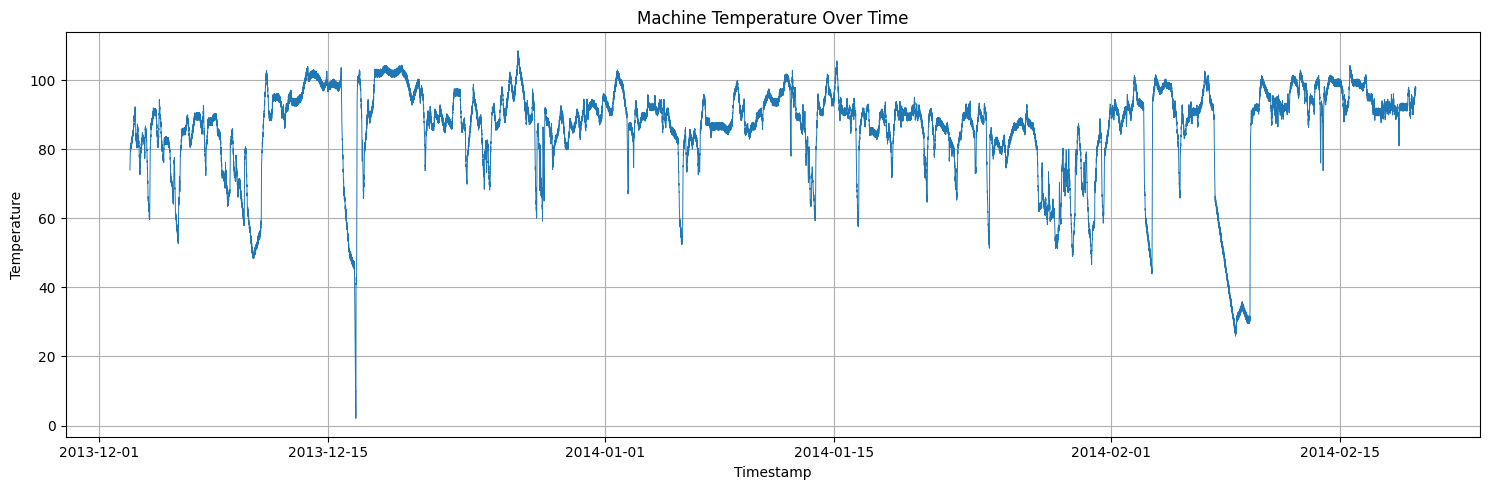

In [ ]:

df["timestamp"] = pd.to_datetime(df["timestamp"])

plt.figure(figsize=(15, 5))

plt.plot(
    df["timestamp"],
    df["value"],
    linewidth=0.7
)

plt.title("Machine Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.grid(True)

plt.tight_layout()
plt.show()


## 2. Data cleaning, NAB labels and chronological split


In [ ]:

# STEP 2.4: DATA CLEANING

# Sort observations by timestamp
df = df.sort_values("timestamp").reset_index(drop=True)

# Remove duplicate timestamps
df = df.drop_duplicates(subset=["timestamp"]).reset_index(drop=True)

# Convert temperature to numeric
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# Handle missing temperature values
df["value"] = df["value"].interpolate(method="linear")

# Remove remaining missing values
df = df.dropna(subset=["value"]).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Missing values:", df["value"].isnull().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

display(df.head())


Cleaned dataset shape: (22683, 2)
Missing values: 0
Duplicate timestamps: 0


,timestamp,value
0,2013-12-02 21:15:00,73.967322
1,2013-12-02 21:20:00,74.935882
2,2013-12-02 21:25:00,76.124162
3,2013-12-02 21:30:00,78.140707
4,2013-12-02 21:35:00,79.329836


In [ ]:

# STEP 2.5: LOAD GROUND-TRUTH LABELS

import json

labels_url = (
    "https://raw.githubusercontent.com/numenta/"
    "NAB/master/labels/combined_labels.json"
)

import requests

response = requests.get(labels_url)
response.raise_for_status()

nab_labels = response.json()

anomaly_timestamps = nab_labels[
    "realKnownCause/machine_temperature_system_failure.csv"
]

anomaly_timestamps = pd.to_datetime(anomaly_timestamps)

# Create point anomaly labels
df["is_anomaly"] = df["timestamp"].isin(
    anomaly_timestamps
).astype(int)

print("Ground-truth anomaly timestamps:")
print(anomaly_timestamps)

print("\nLabel distribution:")
print(df["is_anomaly"].value_counts())

display(df[df["is_anomaly"] == 1])



Ground-truth anomaly timestamps:
DatetimeIndex(['2013-12-11 06:00:00', '2013-12-16 17:25:00',
               '2014-01-28 13:55:00', '2014-02-08 14:30:00'],
              dtype='datetime64[ns]', freq=None)

Label distribution:
is_anomaly
0    22679
1        4
Name: count, dtype: int64


,timestamp,value,is_anomaly
2409,2013-12-11 06:00:00,102.736214,1
3986,2013-12-16 17:25:00,2.084721,1
16328,2014-01-28 13:55:00,51.367154,1
19503,2014-02-08 14:30:00,25.887752,1


In [ ]:

# STEP 2.6: LOAD NAB ANOMALY WINDOWS

windows_url = (
    "https://raw.githubusercontent.com/numenta/"
    "NAB/master/labels/combined_windows.json"
)

windows_response = requests.get(windows_url)
windows_response.raise_for_status()

nab_windows = windows_response.json()

event_windows = nab_windows[
    "realKnownCause/machine_temperature_system_failure.csv"
]

# Boolean mask for observations inside anomaly windows
df["in_anomaly_window"] = False

for start, end in event_windows:
    start = pd.to_datetime(start)
    end = pd.to_datetime(end)

    mask = (
        (df["timestamp"] >= start) &
        (df["timestamp"] <= end)
    )

    df.loc[mask, "in_anomaly_window"] = True

print("Number of NAB anomaly windows:", len(event_windows))
print("Observations inside anomaly windows:",
      df["in_anomaly_window"].sum())

display(df[df["in_anomaly_window"]].head())


Number of NAB anomaly windows: 4
Observations inside anomaly windows: 2268


,timestamp,value,is_anomaly,in_anomaly_window
2126,2013-12-10 06:25:00,53.886196,0,True
2127,2013-12-10 06:30:00,54.113727,0,True
2128,2013-12-10 06:35:00,53.514577,0,True
2129,2013-12-10 06:40:00,54.920342,0,True
2130,2013-12-10 06:45:00,55.162629,0,True


In [ ]:

# STEP 2.7: CHRONOLOGICAL SPLIT

N = len(df)

train_end = int(N * 0.60)
val_end = int(N * 0.80)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Train observations:", len(train_df))
print("Validation observations:", len(val_df))
print("Test observations:", len(test_df))

print("\nTrain time range:")
print(train_df["timestamp"].min(), "to",
      train_df["timestamp"].max())

print("\nValidation time range:")
print(val_df["timestamp"].min(), "to",
      val_df["timestamp"].max())

print("\nTest time range:")
print(test_df["timestamp"].min(), "to",
      test_df["timestamp"].max())


Train observations: 13609
Validation observations: 4537
Test observations: 4537

Train time range:
2013-12-02 21:15:00 to 2014-01-19 03:15:00

Validation time range:
2014-01-19 03:20:00 to 2014-02-03 21:20:00

Test time range:
2014-02-03 21:25:00 to 2014-02-19 15:25:00


## 3. Training subset and scaling


In [ ]:

# STEP 2.8: NORMAL-ONLY TRAINING DATA

normal_train_df = train_df[
    ~train_df["in_anomaly_window"]
].copy()

print("Total training observations:", len(train_df))
print("Normal training observations:", len(normal_train_df))
print("Excluded anomaly observations:",
      len(train_df) - len(normal_train_df))

# Fit scaler only on normal training values
scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(normal_train_df[["value"]])

# Transform complete dataset using training scaler
df["scaled_value"] = scaler.transform(
    df[["value"]]
).flatten()

print("\nScaler fitted using normal training data.")
print("Scaled minimum:", df["scaled_value"].min())
print("Scaled maximum:", df["scaled_value"].max())


Total training observations: 13609
Normal training observations: 12475
Excluded anomaly observations: 1134

Scaler fitted using normal training data.
Scaled minimum: -0.8963918787525451
Scaled maximum: 1.0


In [ ]:

# FIX: Ensure scaled_value exists in normal_train_df

# Recreate normal training data from the updated df
normal_train_df = df.loc[
    (df.index < int(len(df) * 0.60)) &
    (~df["in_anomaly_window"])
].copy()

# Verify the scaled column exists
print("Columns:", normal_train_df.columns.tolist())

# Extract scaled values
train_values = normal_train_df["scaled_value"].to_numpy()

print("Train values shape:", train_values.shape)


Columns: ['timestamp', 'value', 'is_anomaly', 'in_anomaly_window', 'scaled_value']
Train values shape: (12475,)


## 4. Sliding-window preparation


In [ ]:

# STEP 2.9: SLIDING WINDOW GENERATION

WINDOW_SIZE = 12

def create_sequences(values, window_size):
    sequences = []

    for i in range(len(values) - window_size + 1):
        sequences.append(values[i:i + window_size])

    return np.array(sequences)


# Generate sequences from normal training data
train_values = normal_train_df["scaled_value"].values

X_train = create_sequences(
    train_values,
    WINDOW_SIZE
)

# Dense AE will use flattened sequences
X_train_dense = X_train.reshape(
    X_train.shape[0], -1
)

# LSTM AE will use 3D sequences
X_train_lstm = X_train.reshape(
    X_train.shape[0], WINDOW_SIZE, 1
)

print("Training sequence shape:", X_train.shape)
print("Dense AE input shape:", X_train_dense.shape)
print("LSTM AE input shape:", X_train_lstm.shape)


Training sequence shape: (12464, 12)
Dense AE input shape: (12464, 12)
LSTM AE input shape: (12464, 12, 1)


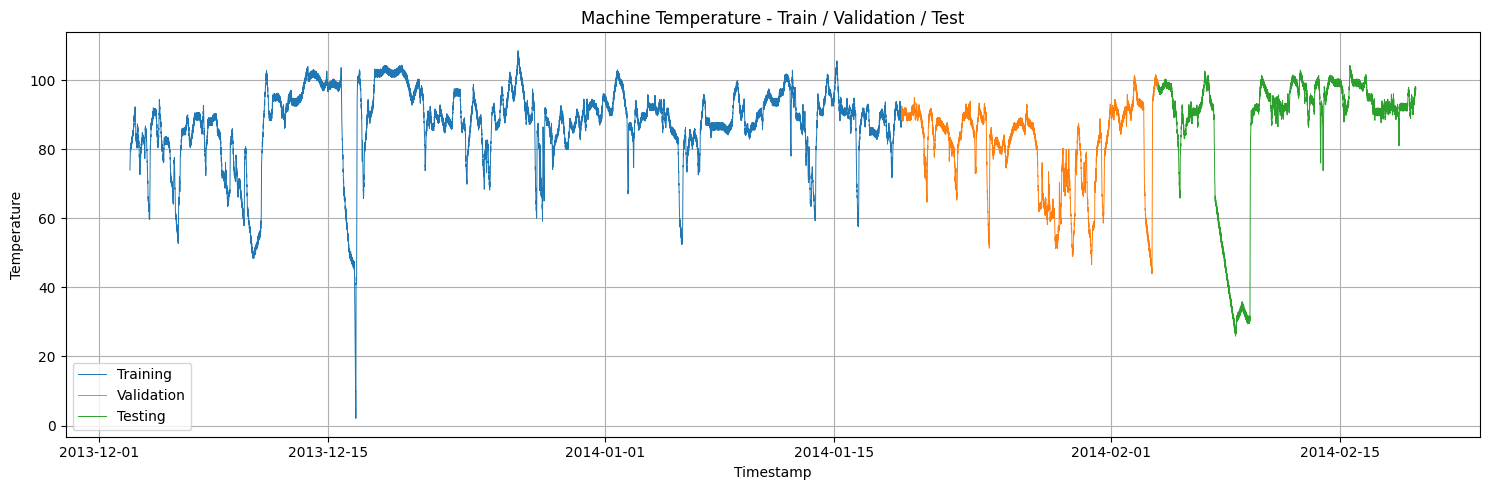

In [ ]:

# STEP 2.10: VISUALIZE CHRONOLOGICAL SPLIT

plt.figure(figsize=(15, 5))

plt.plot(
    train_df["timestamp"],
    train_df["value"],
    label="Training",
    linewidth=0.7
)

plt.plot(
    val_df["timestamp"],
    val_df["value"],
    label="Validation",
    linewidth=0.7
)

plt.plot(
    test_df["timestamp"],
    test_df["value"],
    label="Testing",
    linewidth=0.7
)

plt.title("Machine Temperature - Train / Validation / Test")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


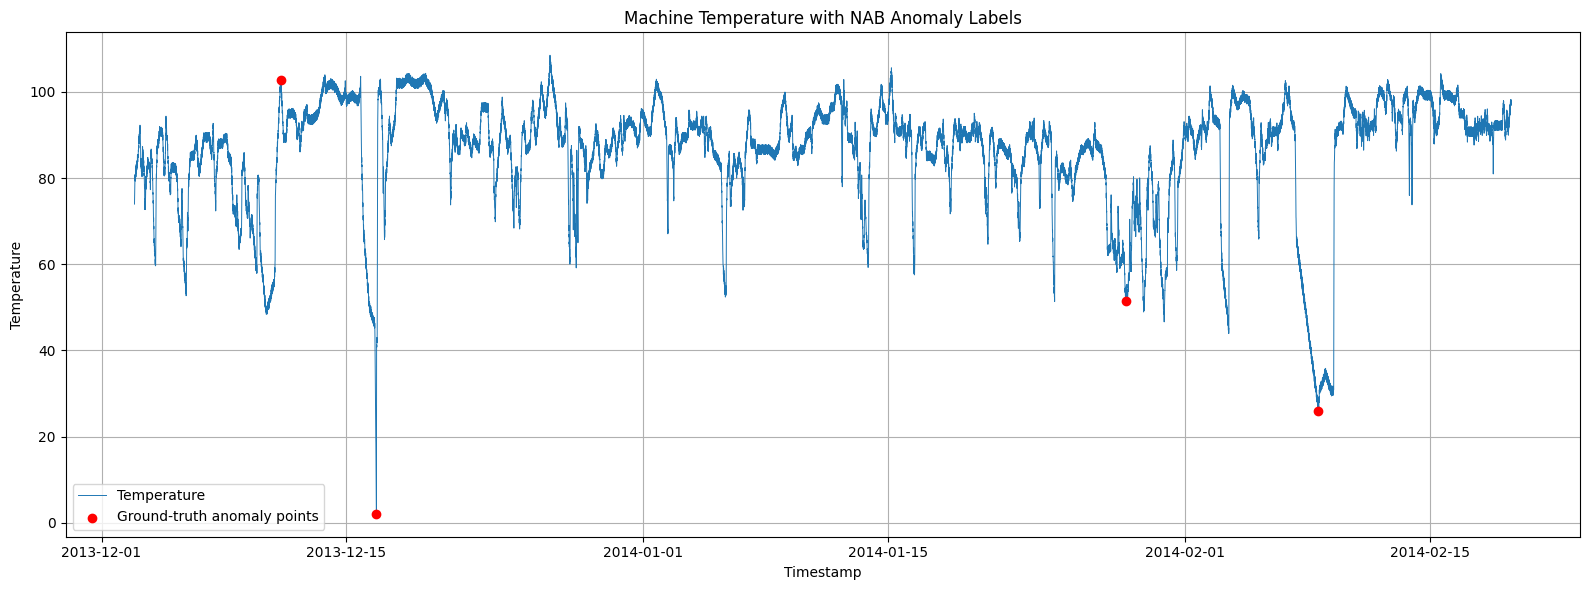

In [ ]:

# STEP 2.11: ANOMALY VISUALIZATION

plt.figure(figsize=(16, 6))

plt.plot(
    df["timestamp"],
    df["value"],
    label="Temperature",
    linewidth=0.7
)

anomaly_points = df[df["is_anomaly"] == 1]

plt.scatter(
    anomaly_points["timestamp"],
    anomaly_points["value"],
    color="red",
    label="Ground-truth anomaly points",
    zorder=5
)

plt.title("Machine Temperature with NAB Anomaly Labels")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 2: PREPROCESSING SUMMARY

print("=" * 50)
print("TEAM 15 - PREPROCESSING SUMMARY")
print("=" * 50)

print("Total observations:", len(df))
print("Training observations:", len(train_df))
print("Validation observations:", len(val_df))
print("Testing observations:", len(test_df))

print("Normal training observations:",
      len(normal_train_df))

print("Ground-truth anomaly points:",
      int(df["is_anomaly"].sum()))

print("Anomaly-window observations:",
      int(df["in_anomaly_window"].sum()))

print("Window size:", WINDOW_SIZE)

print("Dense AE shape:", X_train_dense.shape)
print("LSTM AE shape:", X_train_lstm.shape)

print("=" * 50)
print("PREPROCESSING COMPLETED")


TEAM 15 - PREPROCESSING SUMMARY
Total observations: 22683
Training observations: 13609
Validation observations: 4537
Testing observations: 4537
Normal training observations: 12475
Ground-truth anomaly points: 4
Anomaly-window observations: 2268
Window size: 12
Dense AE shape: (12464, 12)
LSTM AE shape: (12464, 12, 1)
PREPROCESSING COMPLETED


## 5. Dense Autoencoder baseline


In [ ]:

# STEP 3.1: PREPARE VALIDATION AND TEST DATA (FIXED)

# Ensure scaled_value exists in all split DataFrames
train_df["scaled_value"] = scaler.transform(
    train_df[["value"]]
).flatten()

val_df["scaled_value"] = scaler.transform(
    val_df[["value"]]
).flatten()

test_df["scaled_value"] = scaler.transform(
    test_df[["value"]]
).flatten()

# Extract scaled values
val_values = val_df["scaled_value"].to_numpy()
test_values = test_df["scaled_value"].to_numpy()

# Generate sliding windows
X_val = create_sequences(val_values, WINDOW_SIZE)
X_test = create_sequences(test_values, WINDOW_SIZE)

# Dense Autoencoder inputs
X_val_dense = X_val.reshape(X_val.shape[0], -1)
X_test_dense = X_test.reshape(X_test.shape[0], -1)

print("Train:", X_train_dense.shape)
print("Validation:", X_val_dense.shape)
print("Test:", X_test_dense.shape)

print("Step 3.1 completed successfully.")


Train: (12464, 12)
Validation: (4526, 12)
Test: (4526, 12)
Step 3.1 completed successfully.


In [ ]:

# STEP 3.2: BUILD DENSE AUTOENCODER

from tensorflow.keras import layers, models

input_dim = X_train_dense.shape[1]

dense_ae = models.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu"),

    # Bottleneck
    layers.Dense(2, activation="relu"),

    # Decoder
    layers.Dense(4, activation="relu"),
    layers.Dense(8, activation="relu"),

    # Reconstruction output
    layers.Dense(input_dim, activation="sigmoid")
])

dense_ae.compile(
    optimizer="adam",
    loss="mse"
)

dense_ae.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 12)             │           108 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 310 (1.21 KB)

 Trainable params: 310 (1.21 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# STEP 3.3: TRAIN DENSE AUTOENCODER

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = dense_ae.fit(
    X_train_dense,
    X_train_dense,

    validation_data=(
        X_val_dense,
        X_val_dense
    ),

    epochs=50,
    batch_size=32,

    callbacks=[early_stop],
    shuffle=True,
    verbose=1
)


Epoch 1/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0347 - val_loss: 0.0650
Epoch 2/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0270 - val_loss: 0.0677
Epoch 3/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0270 - val_loss: 0.0681
Epoch 4/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0270 - val_loss: 0.0676
Epoch 5/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0270 - val_loss: 0.0680
Epoch 6/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0270 - val_loss: 0.0674


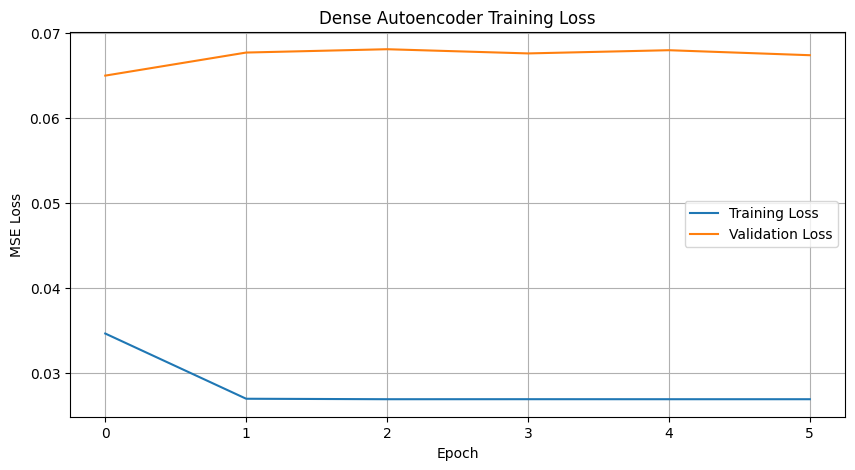

In [ ]:

# STEP 3.4: LOSS GRAPH

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Dense Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# STEP 3.5: RECONSTRUCTION ERROR

# Reconstruct test sequences
X_test_pred = dense_ae.predict(
    X_test_dense,
    verbose=0
)

# Mean squared error for each sequence
reconstruction_error = np.mean(
    np.square(X_test_dense - X_test_pred),
    axis=1
)

print("Reconstruction error shape:",
      reconstruction_error.shape)

print("Mean reconstruction error:",
      reconstruction_error.mean())

print("Maximum reconstruction error:",
      reconstruction_error.max())


Reconstruction error shape: (4526,)
Mean reconstruction error: 0.12123962963888671
Maximum reconstruction error: 1.1897804692761518


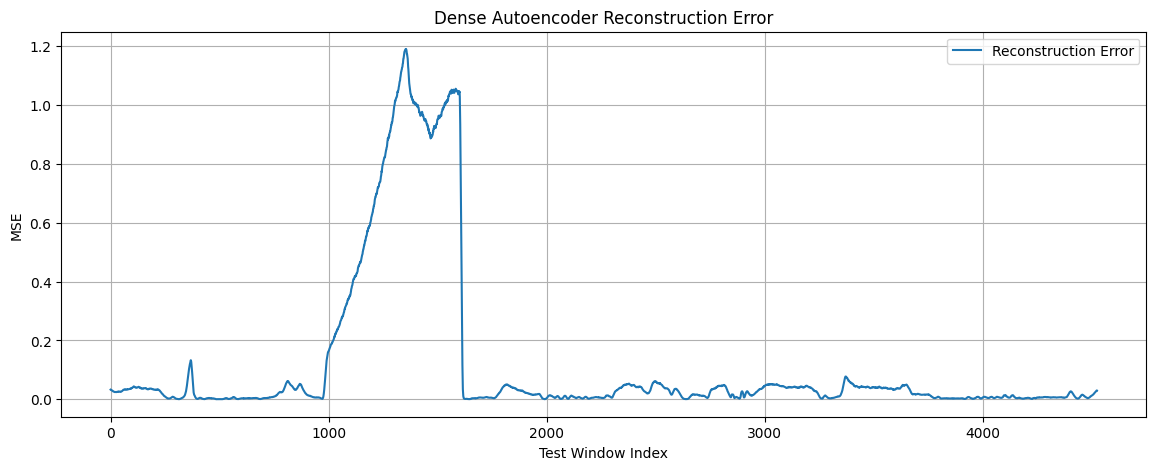

In [ ]:

# STEP 3.6: RECONSTRUCTION ERROR GRAPH

plt.figure(figsize=(14, 5))

plt.plot(
    reconstruction_error,
    label="Reconstruction Error"
)

plt.title("Dense Autoencoder Reconstruction Error")
plt.xlabel("Test Window Index")
plt.ylabel("MSE")

plt.legend()
plt.grid(True)
plt.show()


## 6. Improved Dense Autoencoder


In [ ]:

# STEP 4.2: BUILD IMPROVED AUTOENCODER

from tensorflow.keras import layers, models

input_dim = X_train_dense.shape[1]

improved_ae = models.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder
    layers.Dense(6, activation="relu"),
    layers.Dense(3, activation="relu"),

    # Narrow bottleneck
    layers.Dense(1, activation="relu"),

    # Decoder
    layers.Dense(3, activation="relu"),
    layers.Dense(6, activation="relu"),

    # Output reconstruction
    layers.Dense(input_dim, activation="sigmoid")
])

improved_ae.compile(
    optimizer="adam",
    loss="mse"
)

improved_ae.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            21 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             4 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 6)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 12)             │            84 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217 (868.00 B)

 Trainable params: 217 (868.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# STEP 4.3: TRAIN IMPROVED AUTOENCODER

from tensorflow.keras.callbacks import EarlyStopping

early_stop_improved = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_improved = improved_ae.fit(
    X_train_dense,
    X_train_dense,

    validation_data=(
        X_val_dense,
        X_val_dense
    ),

    epochs=50,
    batch_size=32,

    callbacks=[early_stop_improved],
    shuffle=True,
    verbose=1
)


Epoch 1/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0232 - val_loss: 0.0356
Epoch 2/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0067 - val_loss: 0.0263
Epoch 3/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0045 - val_loss: 0.0211
Epoch 4/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0035 - val_loss: 0.0170
Epoch 5/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0027 - val_loss: 0.0138
Epoch 6/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0022 - val_loss: 0.0114
Epoch 7/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0018 - val_loss: 0.0095
Epoch 8/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0016 - val_loss: 0.0081
Epoch 9/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0014 - val_loss: 0.0069
Epoch 10/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0013 - val_loss: 0.0060
Epoch 11/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 0.0053
Epoch 12/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

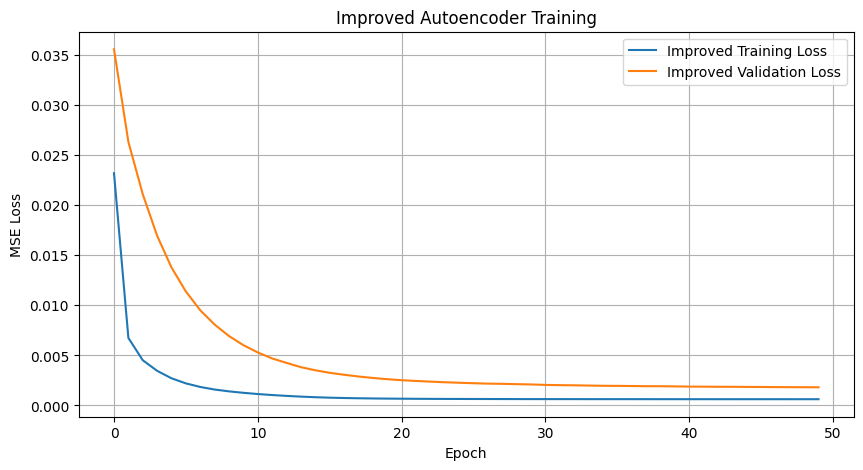

In [ ]:

# STEP 4.4: IMPROVED MODEL LOSS GRAPH

plt.figure(figsize=(10, 5))

plt.plot(
    history_improved.history["loss"],
    label="Improved Training Loss"
)

plt.plot(
    history_improved.history["val_loss"],
    label="Improved Validation Loss"
)

plt.title("Improved Autoencoder Training")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# STEP 4.5: IMPROVED RECONSTRUCTION ERROR

X_test_improved_pred = improved_ae.predict(
    X_test_dense,
    verbose=0
)

improved_reconstruction_error = np.mean(
    np.square(
        X_test_dense - X_test_improved_pred
    ),
    axis=1
)

print("Improved mean reconstruction error:",
      improved_reconstruction_error.mean())

print("Improved maximum reconstruction error:",
      improved_reconstruction_error.max())


Improved mean reconstruction error: 0.021962454080566133
Improved maximum reconstruction error: 0.3508357409754031


In [ ]:

# STEP 4.6: BASELINE VS IMPROVED COMPARISON

comparison = pd.DataFrame({
    "Model": [
        "Dense AE Baseline",
        "Improved Dense AE"
    ],

    "Training Loss": [
        history.history["loss"][-1],
        history_improved.history["loss"][-1]
    ],

    "Validation Loss": [
        history.history["val_loss"][-1],
        history_improved.history["val_loss"][-1]
    ],

    "Mean Test Reconstruction Error": [
        reconstruction_error.mean(),
        improved_reconstruction_error.mean()
    ]
})

display(comparison)


,Model,Training Loss,Validation Loss,Mean Test Reconstruction Error
0,Dense AE Baseline,0.026956,0.067409,0.121240
1,Improved Dense AE,0.000622,0.001815,0.021962


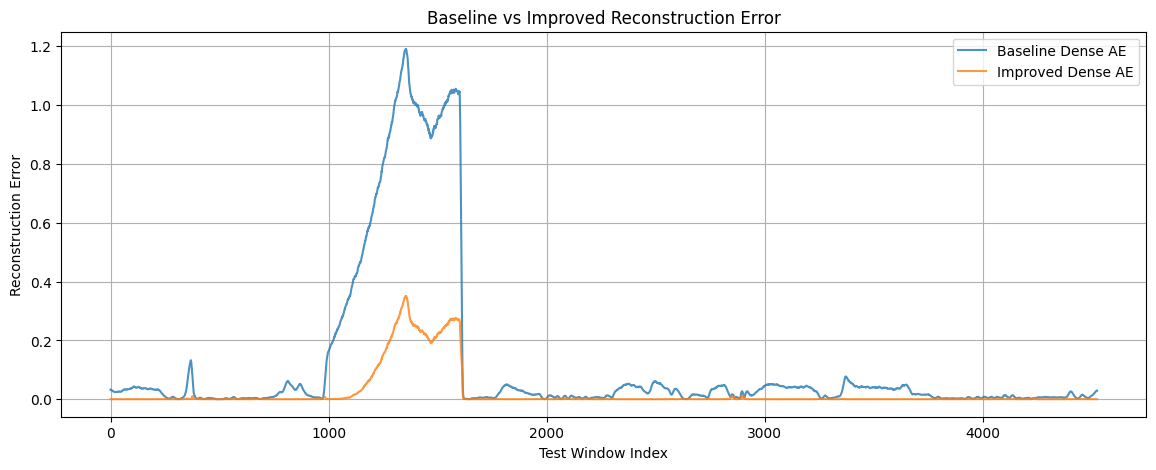

In [ ]:

# STEP 4.7: ERROR COMPARISON GRAPH

plt.figure(figsize=(14, 5))

plt.plot(
    reconstruction_error,
    label="Baseline Dense AE",
    alpha=0.8
)

plt.plot(
    improved_reconstruction_error,
    label="Improved Dense AE",
    alpha=0.8
)

plt.title("Baseline vs Improved Reconstruction Error")
plt.xlabel("Test Window Index")
plt.ylabel("Reconstruction Error")

plt.legend()
plt.grid(True)
plt.show()


## 7. LSTM Autoencoder


In [ ]:

# STEP 5.2: BUILD LSTM AUTOENCODER

from tensorflow.keras import layers, models

lstm_ae = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 1)),

    # Encoder
    layers.LSTM(32, activation="tanh"),
    layers.Dense(16, activation="relu"),

    # Repeat latent representation
    layers.RepeatVector(WINDOW_SIZE),

    # Decoder
    layers.LSTM(32, activation="tanh",
                return_sequences=True),

    # Reconstruct temperature sequence
    layers.TimeDistributed(
        layers.Dense(1, activation="sigmoid")
    )
])

lstm_ae.compile(
    optimizer="adam",
    loss="mse"
)

lstm_ae.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 12, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 12, 32)         │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 12, 1)          │            33 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,185 (43.69 KB)

 Trainable params: 11,185 (43.69 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# STEP 5.3: TRAIN LSTM AUTOENCODER

early_stop_lstm = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_lstm = lstm_ae.fit(
    X_train_lstm,
    X_train_lstm,

    validation_data=(
        X_val.reshape(X_val.shape[0], WINDOW_SIZE, 1),
        X_val.reshape(X_val.shape[0], WINDOW_SIZE, 1)
    ),

    epochs=50,
    batch_size=32,

    callbacks=[early_stop_lstm],
    shuffle=True,
    verbose=1
)


Epoch 1/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - loss: 0.0051 - val_loss: 0.0015
Epoch 2/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 5.1051e-04 - val_loss: 8.3806e-04
Epoch 3/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 3.6470e-04 - val_loss: 6.1803e-04
Epoch 4/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 3.0687e-04 - val_loss: 5.6389e-04
Epoch 5/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - loss: 2.6961e-04 - val_loss: 5.4527e-04
Epoch 6/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.5722e-04 - val_loss: 4.5163e-04
Epoch 7/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 2.3456e-04 - val_loss: 4.6660e-04
Epoch 8/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.2287e-04 - val_loss: 4.2780e-04
Epoch 9/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.1498e-04 - val_loss: 4.1739e-04
Epoch 10/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 2.0799e-04 - val_loss: 4.0363e-04
Epoch 11/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - 

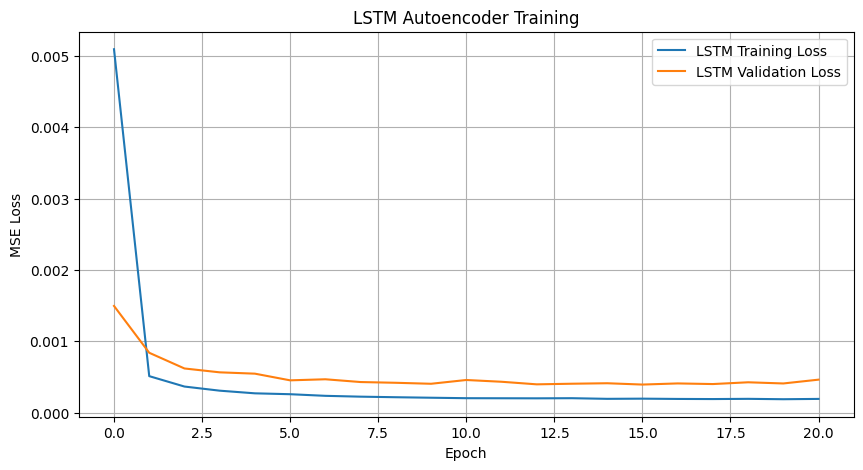

In [ ]:

# STEP 5.4: LSTM LOSS GRAPH

plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="LSTM Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="LSTM Validation Loss"
)

plt.title("LSTM Autoencoder Training")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# STEP 5.5: LSTM RECONSTRUCTION ERROR

X_test_lstm = X_test.reshape(
    X_test.shape[0], WINDOW_SIZE, 1
)

X_test_lstm_pred = lstm_ae.predict(
    X_test_lstm,
    verbose=0
)

lstm_reconstruction_error = np.mean(
    np.square(
        X_test_lstm - X_test_lstm_pred
    ),
    axis=(1, 2)
)

print("LSTM mean reconstruction error:",
      lstm_reconstruction_error.mean())

print("LSTM maximum reconstruction error:",
      lstm_reconstruction_error.max())


LSTM mean reconstruction error: 0.011625131123830092
LSTM maximum reconstruction error: 0.20952092664088953


In [ ]:

# STEP 5.6: THREE-MODEL COMPARISON

model_comparison = pd.DataFrame({
    "Model": [
        "Dense AE",
        "Improved Dense AE",
        "LSTM AE"
    ],

    "Validation Loss": [
        history.history["val_loss"][-1],
        history_improved.history["val_loss"][-1],
        history_lstm.history["val_loss"][-1]
    ],

    "Mean Test Error": [
        reconstruction_error.mean(),
        improved_reconstruction_error.mean(),
        lstm_reconstruction_error.mean()
    ],

    "Max Test Error": [
        reconstruction_error.max(),
        improved_reconstruction_error.max(),
        lstm_reconstruction_error.max()
    ]
})

display(model_comparison)


,Model,Validation Loss,Mean Test Error,Max Test Error
0,Dense AE,0.067409,0.121240,1.189780
1,Improved Dense AE,0.001815,0.021962,0.350836
2,LSTM AE,0.000461,0.011625,0.209521


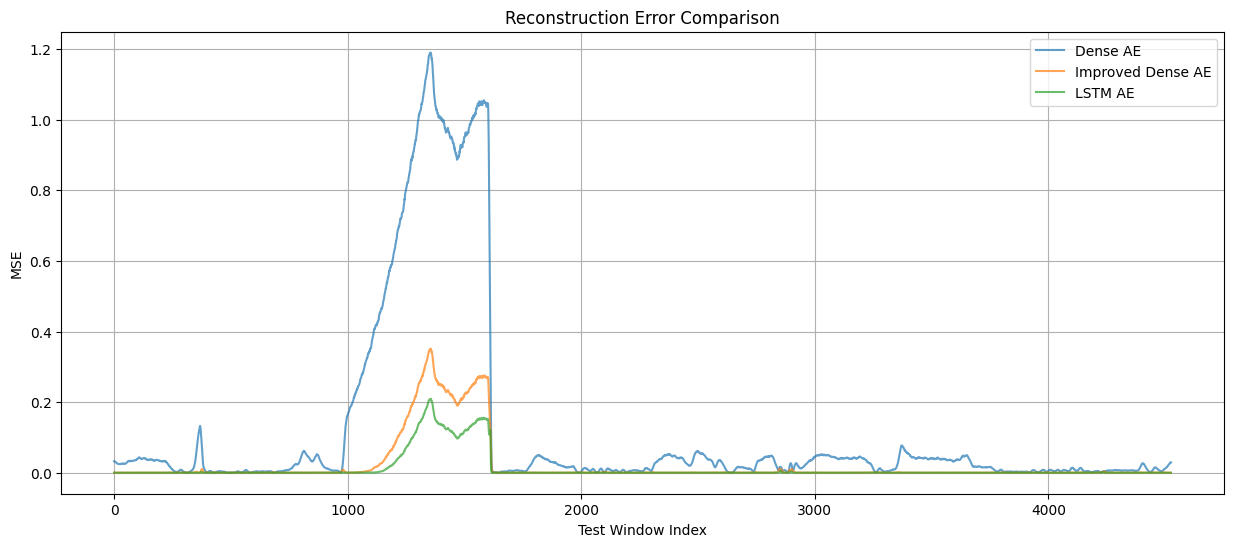

In [ ]:

# STEP 5.7: MODEL ERROR COMPARISON

plt.figure(figsize=(15, 6))

plt.plot(
    reconstruction_error,
    label="Dense AE",
    alpha=0.7
)

plt.plot(
    improved_reconstruction_error,
    label="Improved Dense AE",
    alpha=0.7
)

plt.plot(
    lstm_reconstruction_error,
    label="LSTM AE",
    alpha=0.7
)

plt.title("Reconstruction Error Comparison")
plt.xlabel("Test Window Index")
plt.ylabel("MSE")

plt.legend()
plt.grid(True)
plt.show()


## 8. Validation threshold selection and test evaluation


In [ ]:

# STEP 6.3: PREPARE WINDOW-LEVEL GROUND TRUTH

def create_window_labels(df_split, window_size):
    labels = df_split["in_anomaly_window"].astype(int).to_numpy()

    window_labels = []

    for i in range(len(labels) - window_size + 1):
        window = labels[i:i + window_size]

        # Window is anomalous if any observation overlaps
        # an NAB anomaly window
        window_labels.append(int(window.max() == 1))

    return np.array(window_labels)


y_val = create_window_labels(val_df, WINDOW_SIZE)
y_test = create_window_labels(test_df, WINDOW_SIZE)

print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("Validation anomaly windows:", y_val.sum())
print("Test anomaly windows:", y_test.sum())


Validation labels: (4526,)
Test labels: (4526,)
Validation anomaly windows: 578
Test anomaly windows: 578


In [ ]:

# STEP 6.4: VALIDATION RECONSTRUCTION ERRORS

# Dense AE
X_val_dense_pred = dense_ae.predict(
    X_val_dense,
    verbose=0
)

dense_val_error = np.mean(
    np.square(X_val_dense - X_val_dense_pred),
    axis=1
)

# Improved Dense AE
X_val_improved_pred = improved_ae.predict(
    X_val_dense,
    verbose=0
)

improved_val_error = np.mean(
    np.square(X_val_dense - X_val_improved_pred),
    axis=1
)

# LSTM AE
X_val_lstm = X_val.reshape(
    X_val.shape[0], WINDOW_SIZE, 1
)

X_val_lstm_pred = lstm_ae.predict(
    X_val_lstm,
    verbose=0
)

lstm_val_error = np.mean(
    np.square(X_val_lstm - X_val_lstm_pred),
    axis=(1, 2)
)

print("Validation errors generated.")


Validation errors generated.


In [ ]:

# STEP 6.5: THRESHOLD OPTIMIZATION

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

def find_best_threshold(errors, labels):
    thresholds = np.unique(
        np.percentile(
            errors,
            np.linspace(50, 99.9, 300)
        )
    )

    results = []

    for threshold in thresholds:
        predictions = (errors > threshold).astype(int)

        precision = precision_score(
            labels, predictions, zero_division=0
        )

        recall = recall_score(
            labels, predictions, zero_division=0
        )

        f1 = f1_score(
            labels, predictions, zero_division=0
        )

        results.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    results_df = pd.DataFrame(results)

    best_row = results_df.loc[
        results_df["f1"].idxmax()
    ]

    return best_row, results_df


# Optimize each model
best_dense, dense_threshold_results = find_best_threshold(
    dense_val_error, y_val
)

best_improved, improved_threshold_results = find_best_threshold(
    improved_val_error, y_val
)

best_lstm, lstm_threshold_results = find_best_threshold(
    lstm_val_error, y_val
)

print("Dense AE best threshold:")
display(best_dense)

print("Improved AE best threshold:")
display(best_improved)

print("LSTM AE best threshold:")
display(best_lstm)


Dense AE best threshold:


,146
threshold,0.063619
precision,0.450862
recall,0.904844
f1,0.601841


Improved AE best threshold:


,119
threshold,0.000587
precision,0.335777
recall,0.792388
f1,0.471679


LSTM AE best threshold:


,194
threshold,0.000231
precision,0.300752
recall,0.415225
f1,0.348837


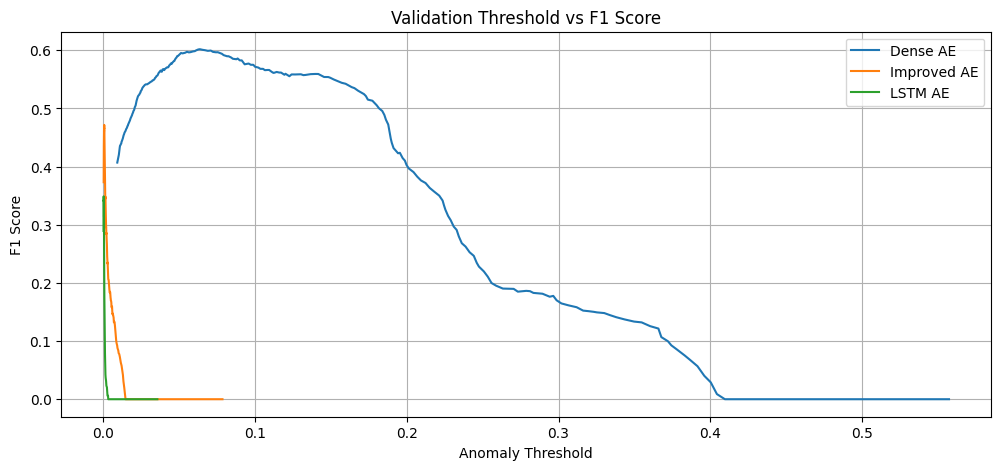

In [ ]:

# STEP 6.6: THRESHOLD-F1 GRAPH

plt.figure(figsize=(12, 5))

plt.plot(
    dense_threshold_results["threshold"],
    dense_threshold_results["f1"],
    label="Dense AE"
)

plt.plot(
    improved_threshold_results["threshold"],
    improved_threshold_results["f1"],
    label="Improved AE"
)

plt.plot(
    lstm_threshold_results["threshold"],
    lstm_threshold_results["f1"],
    label="LSTM AE"
)

plt.title("Validation Threshold vs F1 Score")
plt.xlabel("Anomaly Threshold")
plt.ylabel("F1 Score")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# STEP 6.7: TEST ANOMALY PREDICTIONS

dense_threshold = float(best_dense["threshold"])
improved_threshold = float(best_improved["threshold"])
lstm_threshold = float(best_lstm["threshold"])

y_pred_dense = (
    reconstruction_error > dense_threshold
).astype(int)

y_pred_improved = (
    improved_reconstruction_error > improved_threshold
).astype(int)

y_pred_lstm = (
    lstm_reconstruction_error > lstm_threshold
).astype(int)

print("Test anomaly predictions generated.")


Test anomaly predictions generated.


In [ ]:

# STEP 6.8: TEST PERFORMANCE

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "False Positives": int(
            ((y_true == 0) & (y_pred == 1)).sum()
        ),

        "False Negatives": int(
            ((y_true == 1) & (y_pred == 0)).sum()
        )
    }


test_results = pd.DataFrame([
    evaluate_model(y_test, y_pred_dense, "Dense AE"),
    evaluate_model(y_test, y_pred_improved, "Improved AE"),
    evaluate_model(y_test, y_pred_lstm, "LSTM AE")
])

display(test_results)


,Model,Precision,Recall,F1 Score,False Positives,False Negatives
0,Dense AE,0.821694,0.956747,0.884093,120,25
1,Improved AE,0.572295,0.979239,0.722399,423,12
2,LSTM AE,0.605473,0.918685,0.729897,346,47


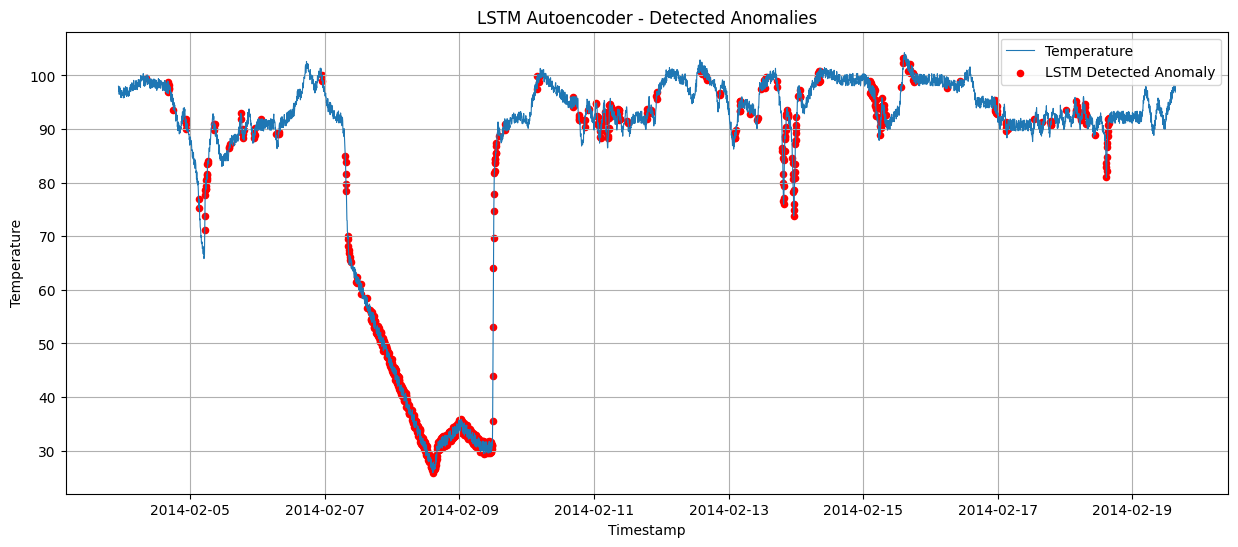

In [ ]:

# STEP 6.9: ANOMALY DETECTION VISUALIZATION

plt.figure(figsize=(15, 6))

plt.plot(
    test_df["timestamp"].iloc[WINDOW_SIZE - 1:],
    test_df["value"].iloc[WINDOW_SIZE - 1:],
    label="Temperature",
    linewidth=0.8
)

predicted_anomalies = np.where(y_pred_lstm == 1)[0]

plt.scatter(
    test_df["timestamp"].iloc[
        predicted_anomalies + WINDOW_SIZE - 1
    ],
    test_df["value"].iloc[
        predicted_anomalies + WINDOW_SIZE - 1
    ],
    color="red",
    label="LSTM Detected Anomaly",
    s=20
)

plt.title("LSTM Autoencoder - Detected Anomalies")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")

plt.legend()
plt.grid(True)
plt.show()


## 9. Operational false-alarm analysis


In [ ]:
# Generate predictions using validation-selected thresholds

dense_test_predictions = (
    reconstruction_error >= best_dense["threshold"]
)

improved_test_predictions = (
    improved_reconstruction_error >= best_improved["threshold"]
)

lstm_test_predictions = (
    lstm_reconstruction_error >= best_lstm["threshold"]
)

print("Test predictions generated.")

Test predictions generated.


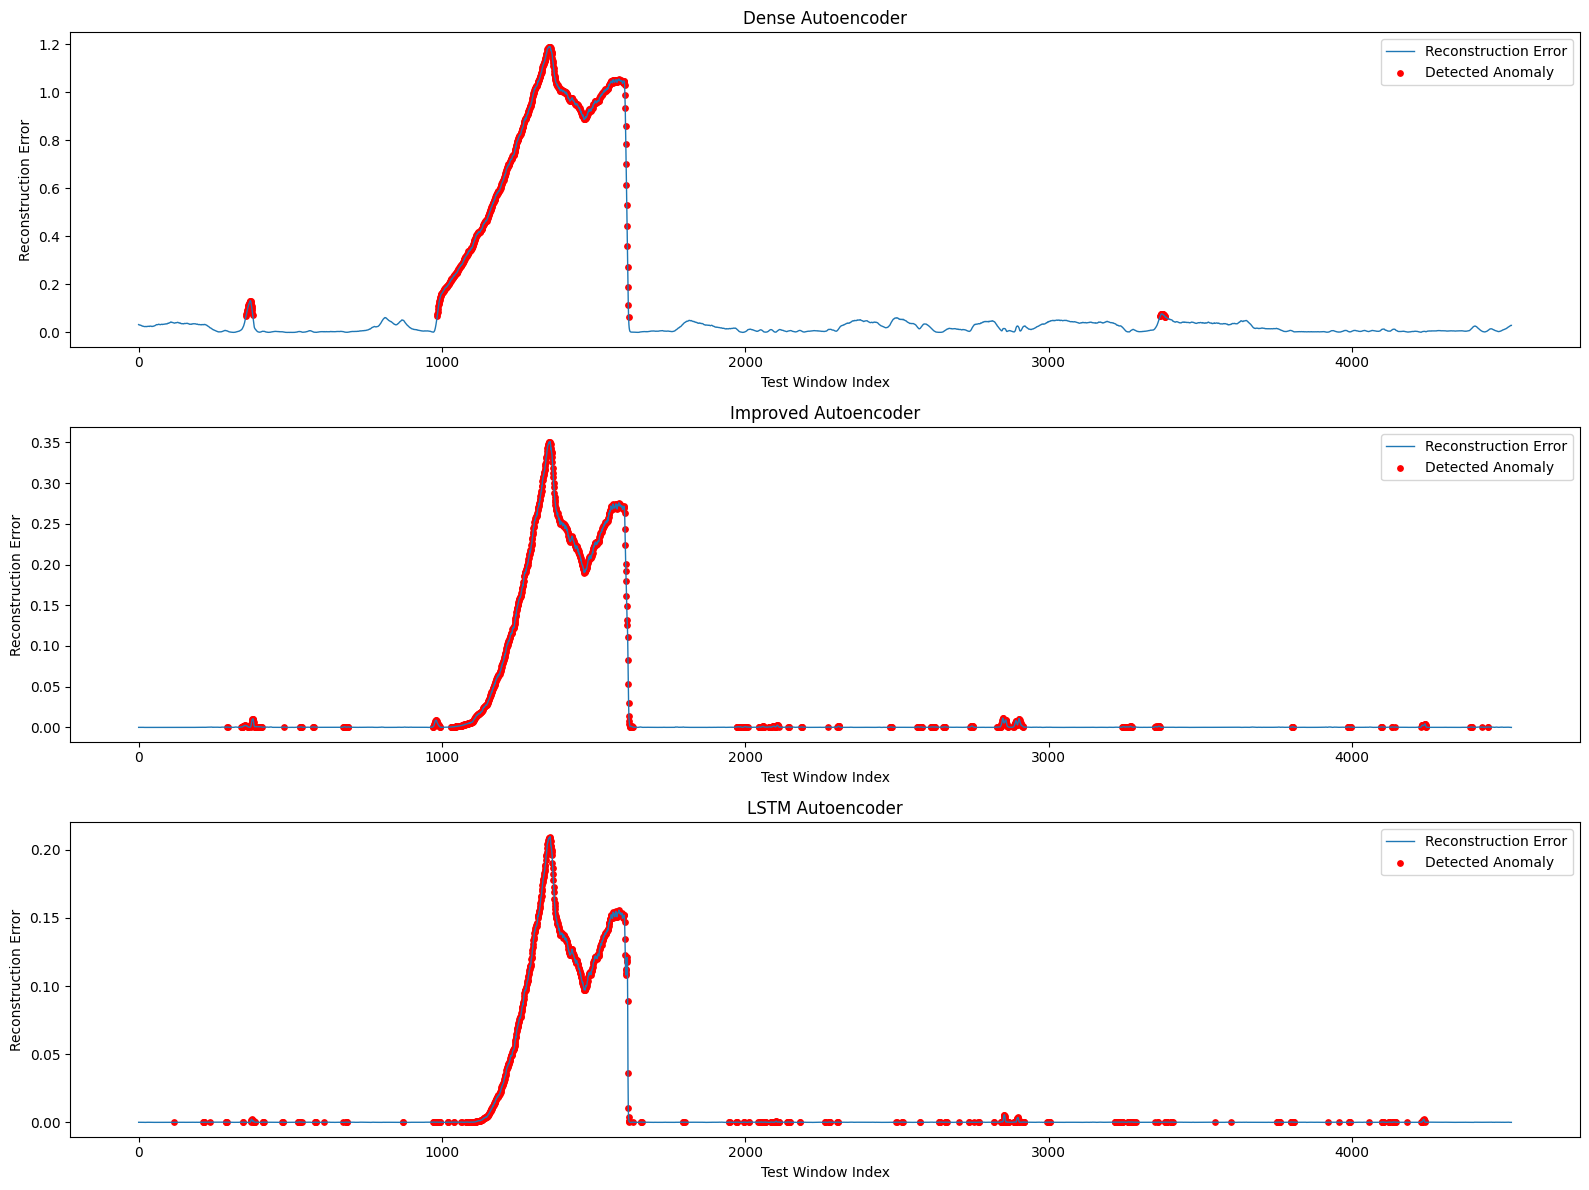

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(16, 12))

models_data = [
    ("Dense Autoencoder", reconstruction_error, dense_test_predictions),
    ("Improved Autoencoder", improved_reconstruction_error,
     improved_test_predictions),
    ("LSTM Autoencoder", lstm_reconstruction_error,
     lstm_test_predictions)
]

for ax, (name, errors, predictions) in zip(axes, models_data):

    ax.plot(errors, label="Reconstruction Error", linewidth=1)

    anomaly_indices = np.where(predictions)[0]

    ax.scatter(
        anomaly_indices,
        errors[anomaly_indices],
        color="red",
        label="Detected Anomaly",
        s=15
    )

    ax.set_title(name)
    ax.set_xlabel("Test Window Index")
    ax.set_ylabel("Reconstruction Error")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
def count_alarm_events(predictions):
    predictions = np.asarray(predictions).astype(int)

    # Count only the beginning of consecutive predicted anomaly windows
    alarm_starts = np.where(
        (predictions == 1) &
        (np.r_[0, predictions[:-1]] == 0)
    )[0]

    return len(alarm_starts)


sampling_interval_minutes = 5  # Verify using your dataset timestamps

test_duration_days = (
    len(test_df) * sampling_interval_minutes / 1440
)

def false_alarms_per_day(predictions, labels):
    predictions = np.asarray(predictions).astype(int)
    labels = np.asarray(labels).astype(int)

    false_alarm_predictions = predictions * (1 - labels)

    false_alarm_events = count_alarm_events(
        false_alarm_predictions
    )

    return false_alarm_events / test_duration_days


dense_false_alarms = false_alarms_per_day(
    dense_test_predictions, y_test
)

improved_false_alarms = false_alarms_per_day(
    improved_test_predictions, y_test
)

lstm_false_alarms = false_alarms_per_day(
    lstm_test_predictions, y_test
)

print("Dense AE:", dense_false_alarms)
print("Improved AE:", improved_false_alarms)
print("LSTM AE:", lstm_false_alarms)

Dense AE: 0.1904342076261847
Improved AE: 3.3008595988538683
LSTM AE: 6.284328851664095


In [ ]:
import pandas as pd

operational_results = pd.DataFrame({
    "Model": [
        "Dense AE",
        "Improved AE",
        "LSTM AE"
    ],
    "Recall": [
        best_dense["recall"],
        best_improved["recall"],
        best_lstm["recall"]
    ],
    "False Alarms/Day": [
        dense_false_alarms,
        improved_false_alarms,
        lstm_false_alarms
    ]
})

display(operational_results)

,Model,Recall,False Alarms/Day
0,Dense AE,0.904844,0.190434
1,Improved AE,0.792388,3.300860
2,LSTM AE,0.415225,6.284329


## 10. Cost-based threshold optimisation


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Prepare validation sequences
X_val_dense = X_val.reshape(X_val.shape[0], -1)
X_val_lstm = X_val.reshape(-1, WINDOW_SIZE, 1)

# Dense Autoencoder validation errors
val_dense_pred = dense_ae.predict(X_val_dense, verbose=0)

val_dense_error = np.mean(
    (X_val_dense - val_dense_pred) ** 2,
    axis=1
)

# Improved Autoencoder validation errors
val_improved_pred = improved_ae.predict(X_val_dense, verbose=0)

val_improved_error = np.mean(
    (X_val_dense - val_improved_pred) ** 2,
    axis=1
)

# LSTM Autoencoder validation errors
val_lstm_pred = lstm_ae.predict(X_val_lstm, verbose=0)

val_lstm_error = np.mean(
    (X_val_lstm - val_lstm_pred) ** 2,
    axis=(1, 2)
)

print("Validation errors generated successfully.")
print("Dense AE:", len(val_dense_error))
print("Improved AE:", len(val_improved_error))
print("LSTM AE:", len(val_lstm_error))

Validation errors generated successfully.
Dense AE: 4526
Improved AE: 4526
LSTM AE: 4526


In [ ]:
# Generate validation labels if they are not already available
y_val = create_window_labels(val_df, WINDOW_SIZE)

# Convert to NumPy
y_val = np.asarray(y_val).astype(int)

print("Validation labels:", len(y_val))
print("Dense errors:", len(val_dense_error))
print("Improved errors:", len(val_improved_error))
print("LSTM errors:", len(val_lstm_error))

assert len(y_val) == len(val_dense_error)
assert len(y_val) == len(val_improved_error)
assert len(y_val) == len(val_lstm_error)

print("Validation dimensions match.")

Validation labels: 4526
Dense errors: 4526
Improved errors: 4526
LSTM errors: 4526
Validation dimensions match.


In [ ]:
MISSED_FAULT_COST = 400000
FALSE_ALARM_COST = 2000

def optimize_threshold_by_cost(errors, labels):

    errors = np.asarray(errors)
    labels = np.asarray(labels).astype(int)

    thresholds = np.unique(
        np.concatenate([
            [0.0],
            errors,
            [errors.max() + 1e-10]
        ])
    )

    best_cost = float("inf")
    best_threshold = None
    best_metrics = None

    for threshold in thresholds:

        predictions = (errors >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            labels,
            predictions,
            labels=[0, 1]
        ).ravel()

        cost = (
            MISSED_FAULT_COST * fn
            + FALSE_ALARM_COST * fp
        )

        if cost < best_cost:

            best_cost = cost
            best_threshold = threshold

            best_metrics = {
                "TP": tp,
                "TN": tn,
                "FP": fp,
                "FN": fn,
                "Recall": tp / (tp + fn) if tp + fn else 0,
                "Precision": tp / (tp + fp) if tp + fp else 0,
                "Cost": cost
            }

    return best_threshold, best_metrics


print("Cost optimization function defined.")

Cost optimization function defined.


In [ ]:
dense_cost_threshold, dense_cost_metrics = optimize_threshold_by_cost(
    val_dense_error, y_val
)

improved_cost_threshold, improved_cost_metrics = optimize_threshold_by_cost(
    val_improved_error, y_val
)

lstm_cost_threshold, lstm_cost_metrics = optimize_threshold_by_cost(
    val_lstm_error, y_val
)

print("Dense AE threshold:", dense_cost_threshold)
print(dense_cost_metrics)

print("\nImproved AE threshold:", improved_cost_threshold)
print(improved_cost_metrics)

print("\nLSTM AE threshold:", lstm_cost_threshold)
print(lstm_cost_metrics)

Dense AE threshold: 0.027794936466592323
{'TP': np.int64(578), 'TN': np.int64(2970), 'FP': np.int64(978), 'FN': np.int64(0), 'Recall': np.float64(1.0), 'Precision': np.float64(0.37146529562982006), 'Cost': np.int64(1956000)}

Improved AE threshold: 0.0001433616594228641
{'TP': np.int64(578), 'TN': np.int64(755), 'FP': np.int64(3193), 'FN': np.int64(0), 'Recall': np.float64(1.0), 'Precision': np.float64(0.15327499337045877), 'Cost': np.int64(6386000)}

LSTM AE threshold: 4.9426522767112894e-05
{'TP': np.int64(578), 'TN': np.int64(19), 'FP': np.int64(3929), 'FN': np.int64(0), 'Recall': np.float64(1.0), 'Precision': np.float64(0.12824495229642777), 'Cost': np.int64(7858000)}


In [ ]:
cost_comparison = pd.DataFrame([
    {"Model": "Dense AE", **dense_cost_metrics},
    {"Model": "Improved AE", **improved_cost_metrics},
    {"Model": "LSTM AE", **lstm_cost_metrics}
])

display(cost_comparison.sort_values("Cost"))

,Model,TP,TN,FP,FN,Recall,Precision,Cost
0,Dense AE,578,2970,978,0,1.0,0.371465,1956000
1,Improved AE,578,755,3193,0,1.0,0.153275,6386000
2,LSTM AE,578,19,3929,0,1.0,0.128245,7858000


In [ ]:
dense_cost_test_pred = (
    reconstruction_error >= dense_cost_threshold
).astype(int)

improved_cost_test_pred = (
    improved_reconstruction_error >= improved_cost_threshold
).astype(int)

lstm_cost_test_pred = (
    lstm_reconstruction_error >= lstm_cost_threshold
).astype(int)

print("Cost-optimized test predictions generated.")

print("Dense AE:", len(dense_cost_test_pred))
print("Improved AE:", len(improved_cost_test_pred))
print("LSTM AE:", len(lstm_cost_test_pred))

Cost-optimized test predictions generated.
Dense AE: 4526
Improved AE: 4526
LSTM AE: 4526


## 11. Final cost-threshold test comparison


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

def evaluate_model(name, predictions, labels):
    predictions = np.asarray(predictions).astype(int)
    labels = np.asarray(labels).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions, zero_division=0),
        "F1": f1_score(labels, predictions, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Cost_Rs": 400000 * fn + 2000 * fp
    }

final_results = pd.DataFrame([
    evaluate_model("Dense AE", dense_cost_test_pred, y_test),
    evaluate_model("Improved AE", improved_cost_test_pred, y_test),
    evaluate_model("LSTM AE", lstm_cost_test_pred, y_test)
])

display(final_results.sort_values("Cost_Rs"))

,Model,Precision,Recall,F1,TP,FP,FN,TN,Cost_Rs
1,Improved AE,0.164669,0.998270,0.282705,577,2927,1,1021,6254000
2,LSTM AE,0.128131,1.000000,0.227157,578,3933,0,15,7866000
0,Dense AE,0.283957,0.958478,0.438118,554,1397,24,2551,12394000


In [ ]:
for _, row in final_results.iterrows():

    print("\nModel:", row["Model"])

    print("Recall >= 0.85:",
          row["Recall"] >= 0.85)

    print("Cost (₹):",
          row["Cost_Rs"])

    print("Recall:",
          round(row["Recall"], 4))

    print("False Positives:",
          int(row["FP"]))

    print("False Negatives:",
          int(row["FN"]))


Model: Dense AE
Recall >= 0.85: True
Cost (₹): 12394000
Recall: 0.9585
False Positives: 1397
False Negatives: 24

Model: Improved AE
Recall >= 0.85: True
Cost (₹): 6254000
Recall: 0.9983
False Positives: 2927
False Negatives: 1

Model: LSTM AE
Recall >= 0.85: True
Cost (₹): 7866000
Recall: 1.0
False Positives: 3933
False Negatives: 0
